# KXHIGHNY, one week of Kalshi market data

Loaded from the `kalbt-recon-db` Postgres container (read-only SELECTs). Times on all axes are America/New_York; the database stores UTC bar-end times.

## 1. Setup

Check that the row counts match what was loaded (7 events, 42 markets, about 41,000 bars).

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Put the repo root (the folder holding db/connect.py) on sys.path.
root = Path.cwd().resolve()
while not (root / "db" / "connect.py").exists():
    root = root.parent
sys.path.insert(0, str(root))

from db.connect import connect

EVENT = "KXHIGHNY-26NOV22"  # the event used in sections 4-6
TZ = "America/New_York"
SERIES = "KXHIGHNY"


def query(cur, sql, params):
    cur.execute(sql, params)
    return pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])


with connect() as conn, conn.cursor() as cur:
    event = query(cur, "SELECT ticker, event_date FROM event WHERE series_ticker = %s ORDER BY event_date", (SERIES,))
    market = query(cur, """
        SELECT m.ticker, m.event_ticker, m.strike_type, m.floor_strike, m.cap_strike,
               m.open_time, m.close_time, m.result, m.settled_at
        FROM market m JOIN event e ON e.ticker = m.event_ticker
        WHERE e.series_ticker = %s""", (SERIES,))
    candle = query(cur, """
        SELECT c.market_ticker, c.ts, c.yes_bid, c.yes_ask, c.volume
        FROM candle c
        JOIN market m ON m.ticker = c.market_ticker
        JOIN event e ON e.ticker = m.event_ticker
        WHERE e.series_ticker = %s
        ORDER BY c.market_ticker, c.ts""", (SERIES,))

# Decimal -> float, timestamps -> UTC and New York.
for col in ["floor_strike", "cap_strike"]:
    market[col] = market[col].astype(float)
for col in ["yes_bid", "yes_ask", "volume"]:
    candle[col] = candle[col].astype(float)
for col in ["open_time", "close_time", "settled_at"]:
    market[col] = pd.to_datetime(market[col], utc=True)
candle["ts"] = pd.to_datetime(candle["ts"], utc=True)
candle["ts_ny"] = candle["ts"].dt.tz_convert(TZ)


# Readable label per market, plus a sort key so markets run from low strike to high strike.
def make_label(row):
    if row.strike_type == "less":
        text = f"< {row.cap_strike:g}"
    elif row.strike_type == "greater":
        text = f"> {row.floor_strike:g}"
    else:
        text = f"{row.floor_strike:g}-{row.cap_strike:g}"
    return f"{text} ({row.result})"


market["label"] = market.apply(make_label, axis=1)
market["strike_sort"] = market["floor_strike"].fillna(-1e9)  # 'less' markets have no floor: first
market = market.sort_values(["event_ticker", "strike_sort"]).reset_index(drop=True)
candle = candle.merge(market[["ticker", "event_ticker", "label"]], left_on="market_ticker", right_on="ticker")

print("events :", len(event))
print("markets:", len(market))
print("candles:", len(candle))
market[["ticker", "strike_type", "floor_strike", "cap_strike", "label"]].head(6)

events : 7
markets: 42
candles: 41158


,ticker,strike_type,floor_strike,cap_strike,label
0,KXHIGHNY-26NOV16-T52,less,NaN,52.0,< 52 (no)
1,KXHIGHNY-26NOV16-B52.5,between,52.0,53.0,52-53 (no)
2,KXHIGHNY-26NOV16-B54.5,between,54.0,55.0,54-55 (yes)
3,KXHIGHNY-26NOV16-B56.5,between,56.0,57.0,56-57 (no)
4,KXHIGHNY-26NOV16-B58.5,between,58.0,59.0,58-59 (no)
5,KXHIGHNY-26NOV16-T59,greater,59.0,NaN,> 59 (no)


## 2. Overview per event

Every event should have 6 markets; compare bar counts and volumes across days.

In [2]:
overview = candle.groupby("event_ticker").agg(
    bars=("ts", "size"),
    total_volume=("volume", "sum"),
    first_bar=("ts_ny", "min"),
    last_bar=("ts_ny", "max"),
)
overview.insert(0, "markets", market.groupby("event_ticker")["ticker"].size())
overview.insert(0, "event_date", event.set_index("ticker")["event_date"])
overview

,event_date,markets,bars,total_volume,first_bar,last_bar
event_ticker,,,,,,
KXHIGHNY-26NOV16,2026-11-16,6,6062,155795.37,2026-11-15 10:01:00-05:00,2026-11-17 01:00:00-05:00
KXHIGHNY-26NOV17,2026-11-17,6,5755,152880.50,2026-11-16 10:01:00-05:00,2026-11-18 01:00:00-05:00
KXHIGHNY-26NOV18,2026-11-18,6,5638,220548.91,2026-11-17 10:01:00-05:00,2026-11-19 01:00:00-05:00
KXHIGHNY-26NOV19,2026-11-19,6,5761,161105.26,2026-11-18 10:01:00-05:00,2026-11-20 01:00:00-05:00
KXHIGHNY-26NOV20,2026-11-20,6,5901,169435.63,2026-11-19 10:01:00-05:00,2026-11-21 01:00:00-05:00
KXHIGHNY-26NOV21,2026-11-21,6,5928,162101.35,2026-11-20 10:01:00-05:00,2026-11-22 01:00:00-05:00
KXHIGHNY-26NOV22,2026-11-22,6,6113,213125.83,2026-11-21 10:01:00-05:00,2026-11-23 01:00:00-05:00


## 3. One figure per event day

Top: ask (solid) and bid (dashed) per market, as step lines (a gap means no bid or no ask); the dotted vertical line is the close. Bottom: volume in 15-minute buckets, all six markets together.

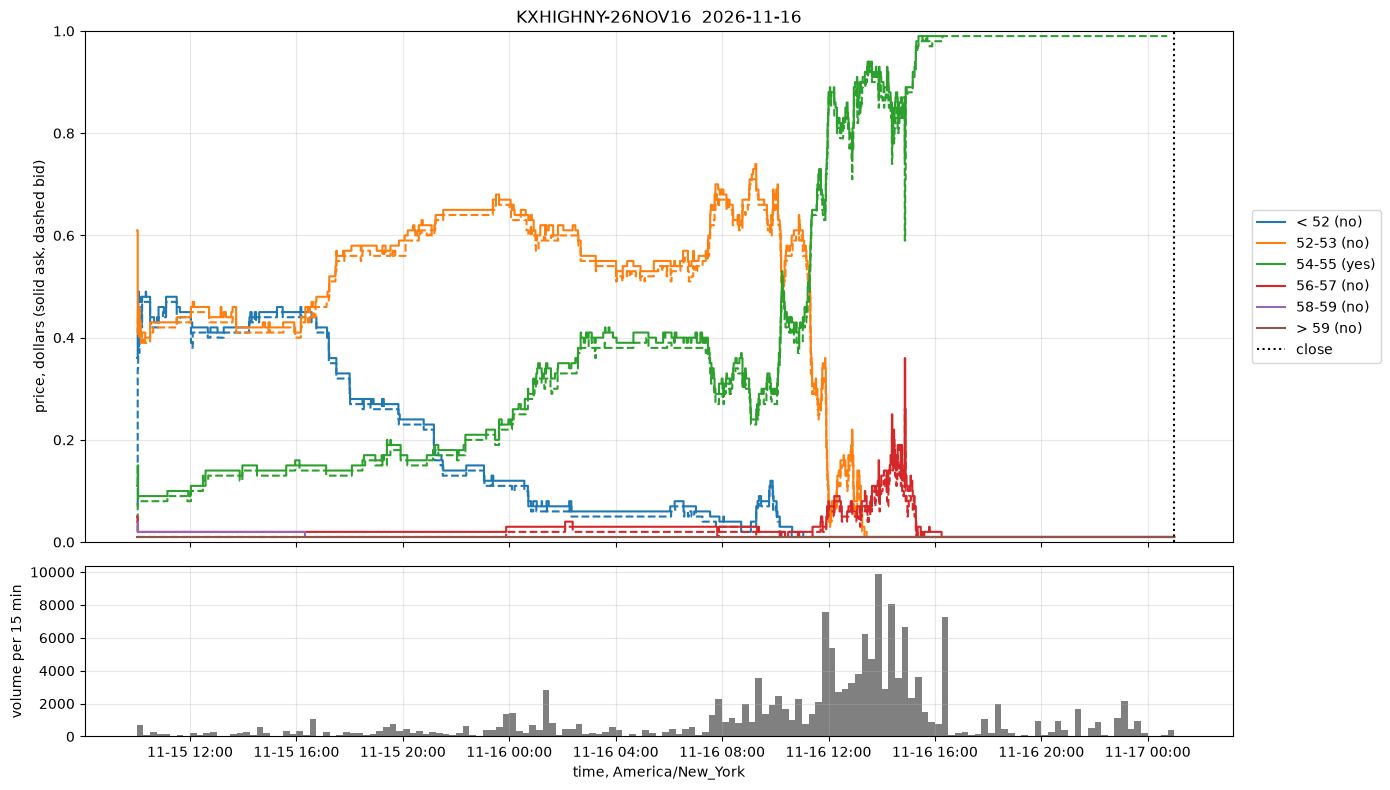

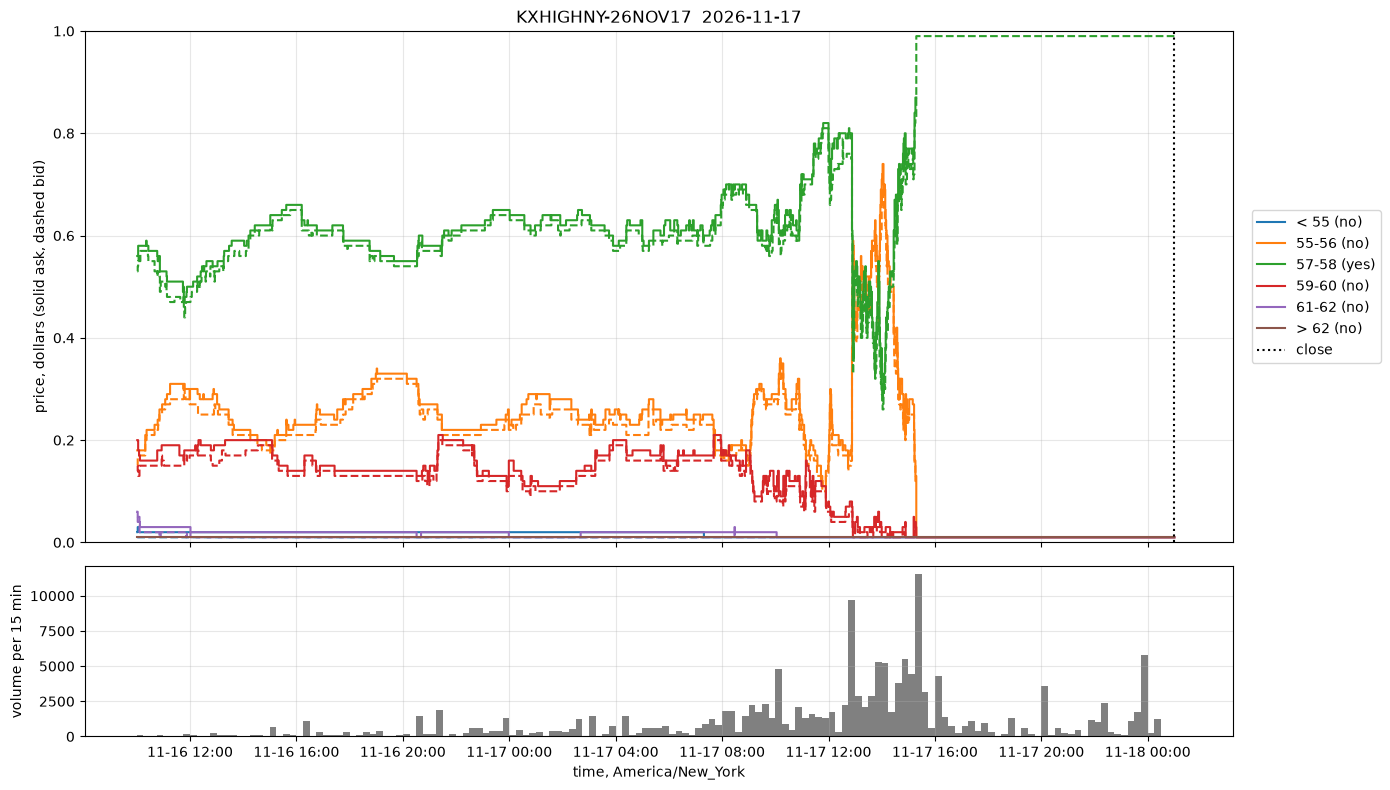

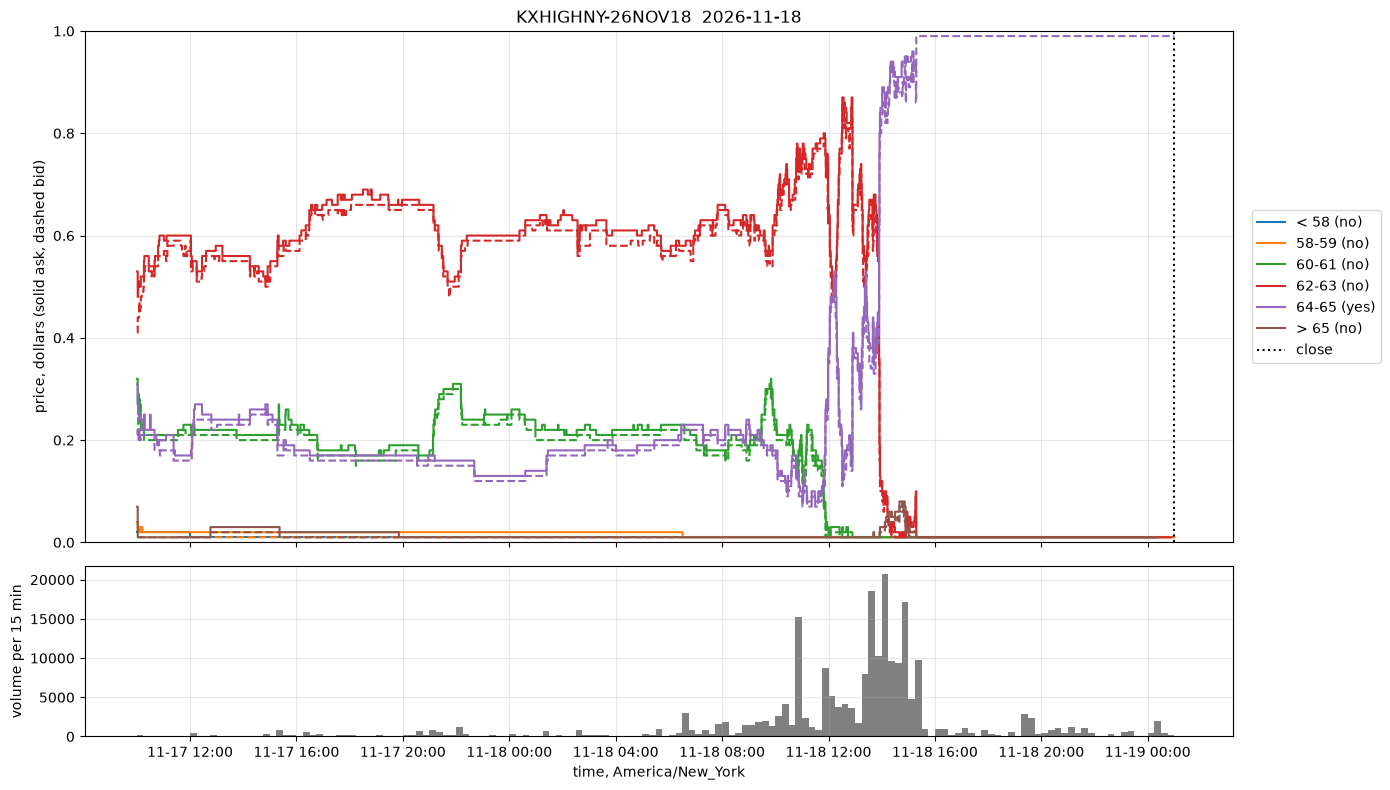

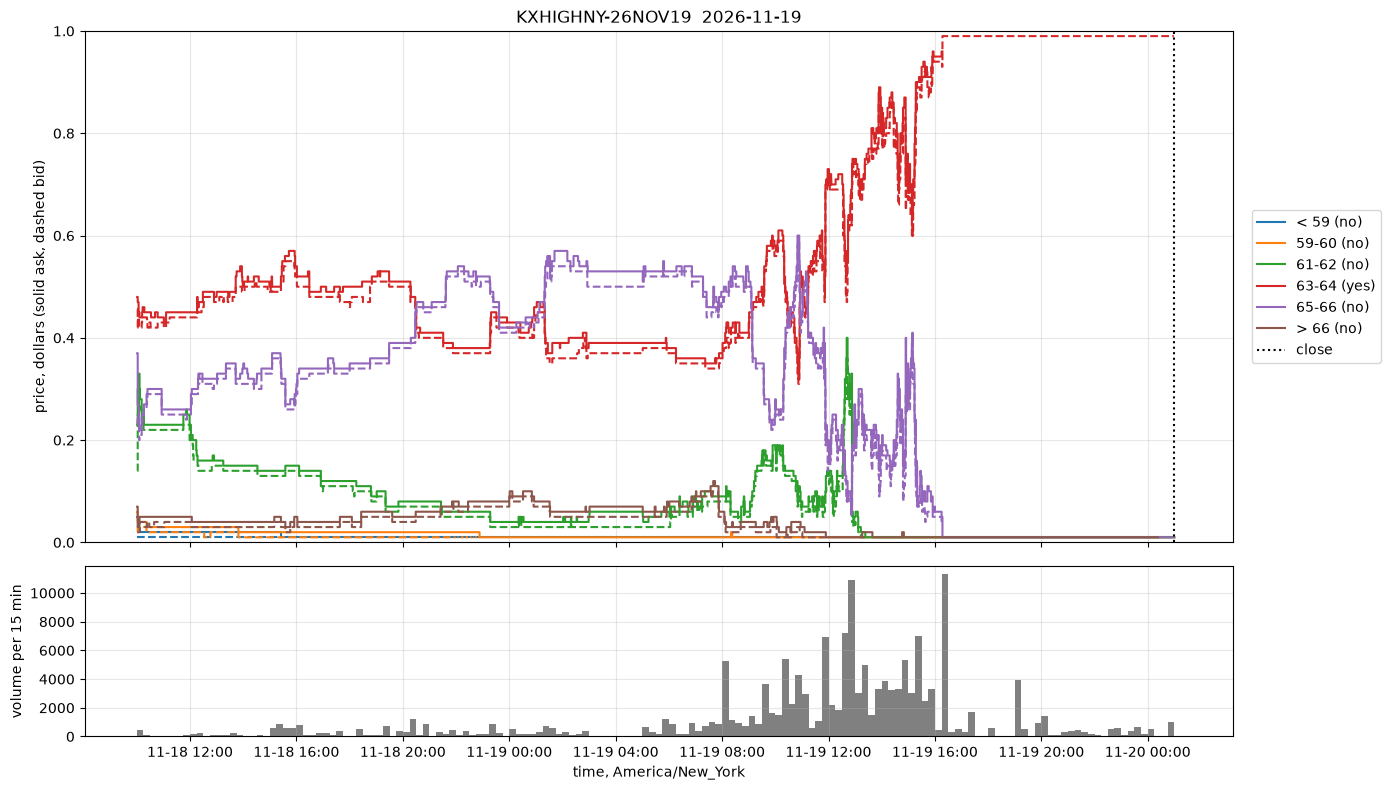

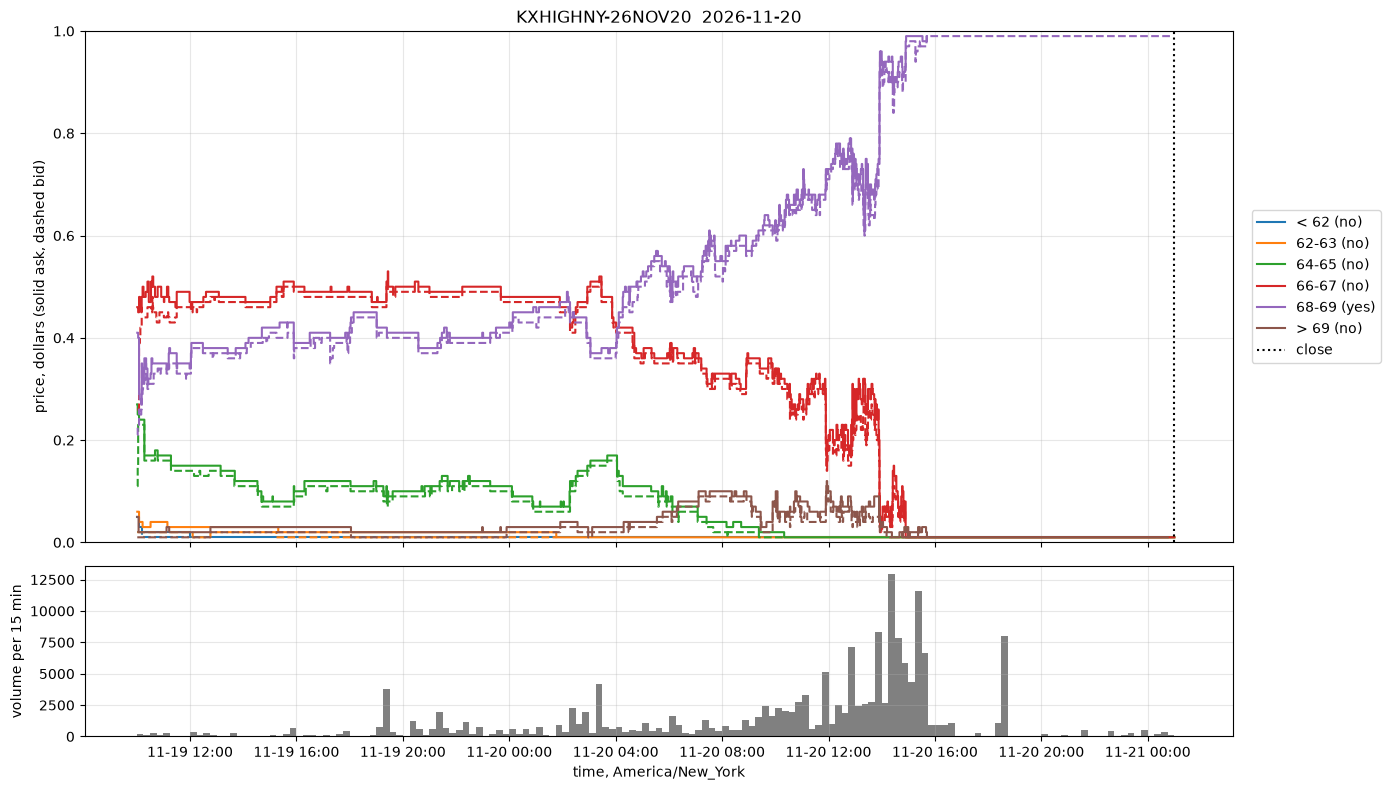

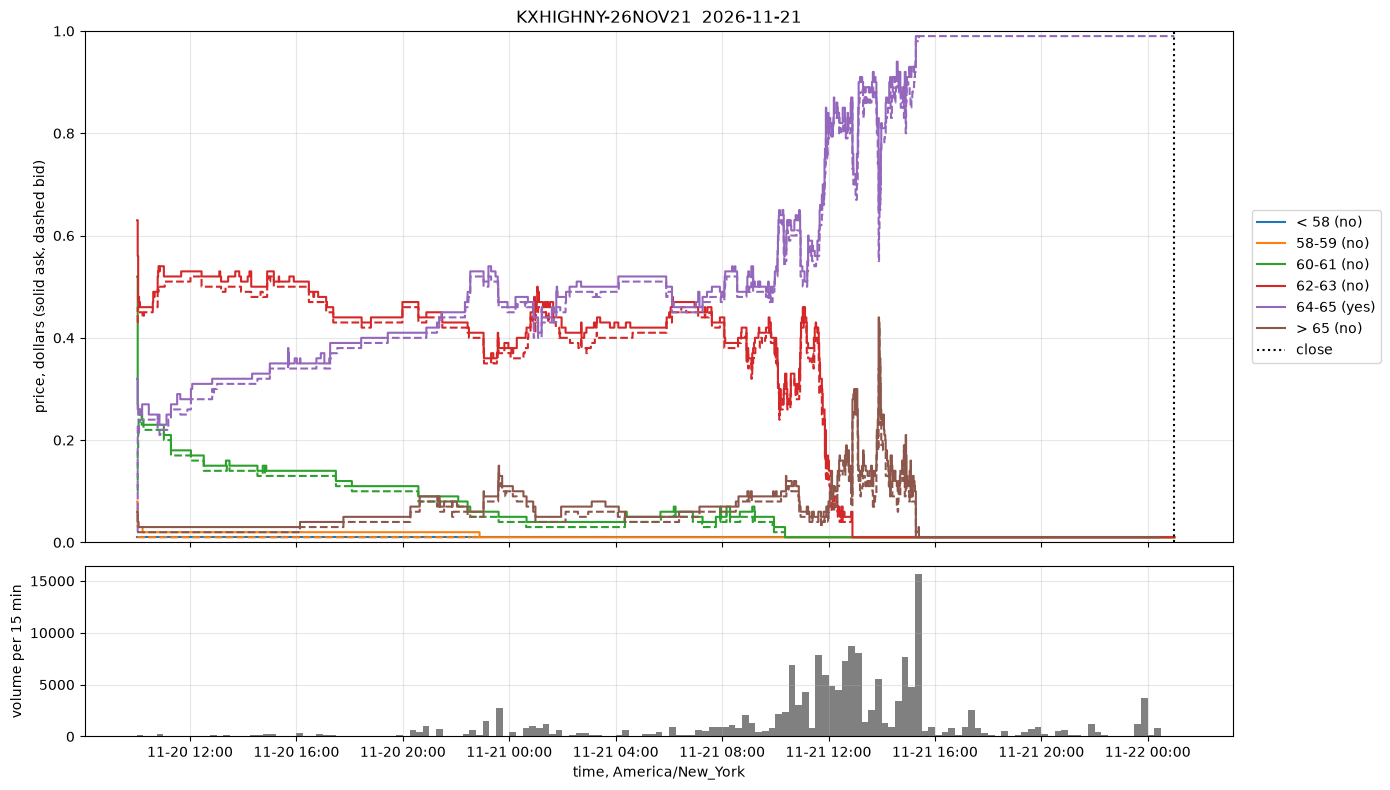

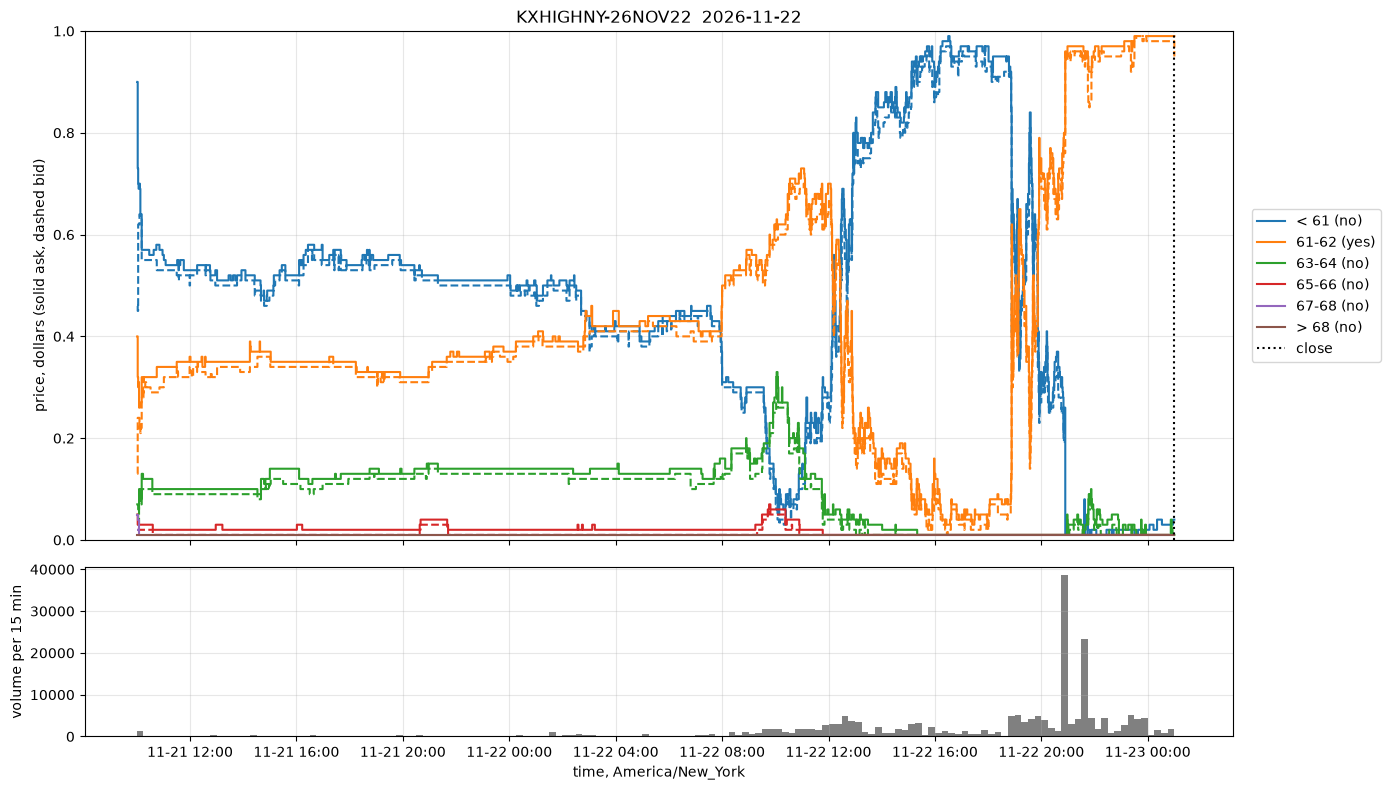

In [3]:
colors = plt.get_cmap("tab10").colors

for _, ev in event.iterrows():
    ev_markets = market[market["event_ticker"] == ev.ticker]
    ev_candles = candle[candle["event_ticker"] == ev.ticker]

    fig, (ax_price, ax_vol) = plt.subplots(
        2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
    )
    for i, m in enumerate(ev_markets.itertuples()):
        bars = ev_candles[ev_candles["market_ticker"] == m.ticker]
        ax_price.plot(bars["ts_ny"], bars["yes_ask"], drawstyle="steps-post", color=colors[i], label=m.label)
        ax_price.plot(bars["ts_ny"], bars["yes_bid"], drawstyle="steps-post", color=colors[i], linestyle="--")
    close_ny = ev_markets["close_time"].iloc[0].tz_convert(TZ)
    ax_price.axvline(close_ny, color="black", linestyle=":", label="close")
    ax_price.set_ylim(0, 1)
    ax_price.set_ylabel("price, dollars (solid ask, dashed bid)")
    ax_price.set_title(f"{ev.ticker}  {ev.event_date}")
    ax_price.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
    ax_price.grid(alpha=0.3)

    volume = ev_candles.set_index("ts_ny")["volume"].resample("15min").sum()
    ax_vol.bar(volume.index, volume.values, width=15 / 1440, align="edge", color="gray")
    ax_vol.set_ylabel("volume per 15 min")
    ax_vol.set_xlabel("time, America/New_York")
    ax_vol.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M", tz=TZ))
    ax_vol.grid(alpha=0.3)

    fig.tight_layout()
    plt.show()

## 4. Bar density

Bars exist only for minutes with activity. The strip shows one row per market (dark = a bar exists); the table gives the counts.

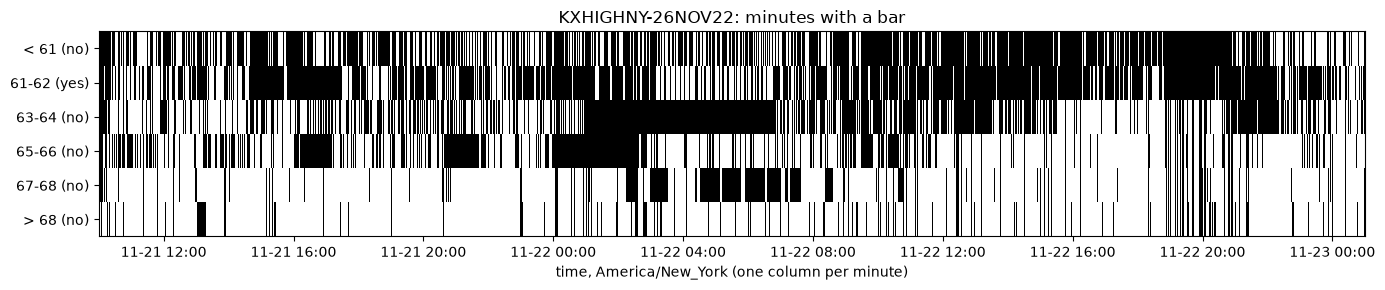

,bars,open_minutes,share_with_bar
label,,,
< 61 (no),1556,2340.0,0.665
61-62 (yes),1644,2340.0,0.703
63-64 (no),1266,2340.0,0.541
65-66 (no),877,2340.0,0.375
67-68 (no),471,2340.0,0.201
> 68 (no),299,2340.0,0.128


In [4]:
ev_markets = market[market["event_ticker"] == EVENT].reset_index(drop=True)
ev_candles = candle[candle["event_ticker"] == EVENT]

start = ev_markets["open_time"].min().floor("min")
end = ev_markets["close_time"].max().ceil("min")
n_minutes = int((end - start) / pd.Timedelta("1min")) + 1

strip = np.zeros((len(ev_markets), n_minutes))
for row, m in enumerate(ev_markets.itertuples()):
    ts = ev_candles.loc[ev_candles["market_ticker"] == m.ticker, "ts"]
    minute_index = ((ts - start) / pd.Timedelta("1min")).astype(int)
    strip[row, minute_index.values] = 1

fig, ax = plt.subplots(figsize=(14, 3))
extent = [mdates.date2num(start), mdates.date2num(end), len(ev_markets), 0]
ax.imshow(strip, aspect="auto", interpolation="nearest", cmap="Greys", extent=extent)
ax.set_yticks(np.arange(len(ev_markets)) + 0.5)
ax.set_yticklabels(ev_markets["label"])
ax.xaxis_date(tz=TZ)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M", tz=TZ))
ax.set_xlabel("time, America/New_York (one column per minute)")
ax.set_title(f"{EVENT}: minutes with a bar")
fig.tight_layout()
plt.show()

density = ev_markets.set_index("label")[["open_time", "close_time"]].copy()
density["bars"] = ev_candles.groupby("label").size()
density["open_minutes"] = (density["close_time"] - density["open_time"]) / pd.Timedelta("1min")
density["share_with_bar"] = (density["bars"] / density["open_minutes"]).round(3)
density[["bars", "open_minutes", "share_with_bar"]]

## 5. Spread

Spread = ask minus bid, only where both exist. Look for negative or zero spreads (crossed or locked quotes) and very wide spreads.

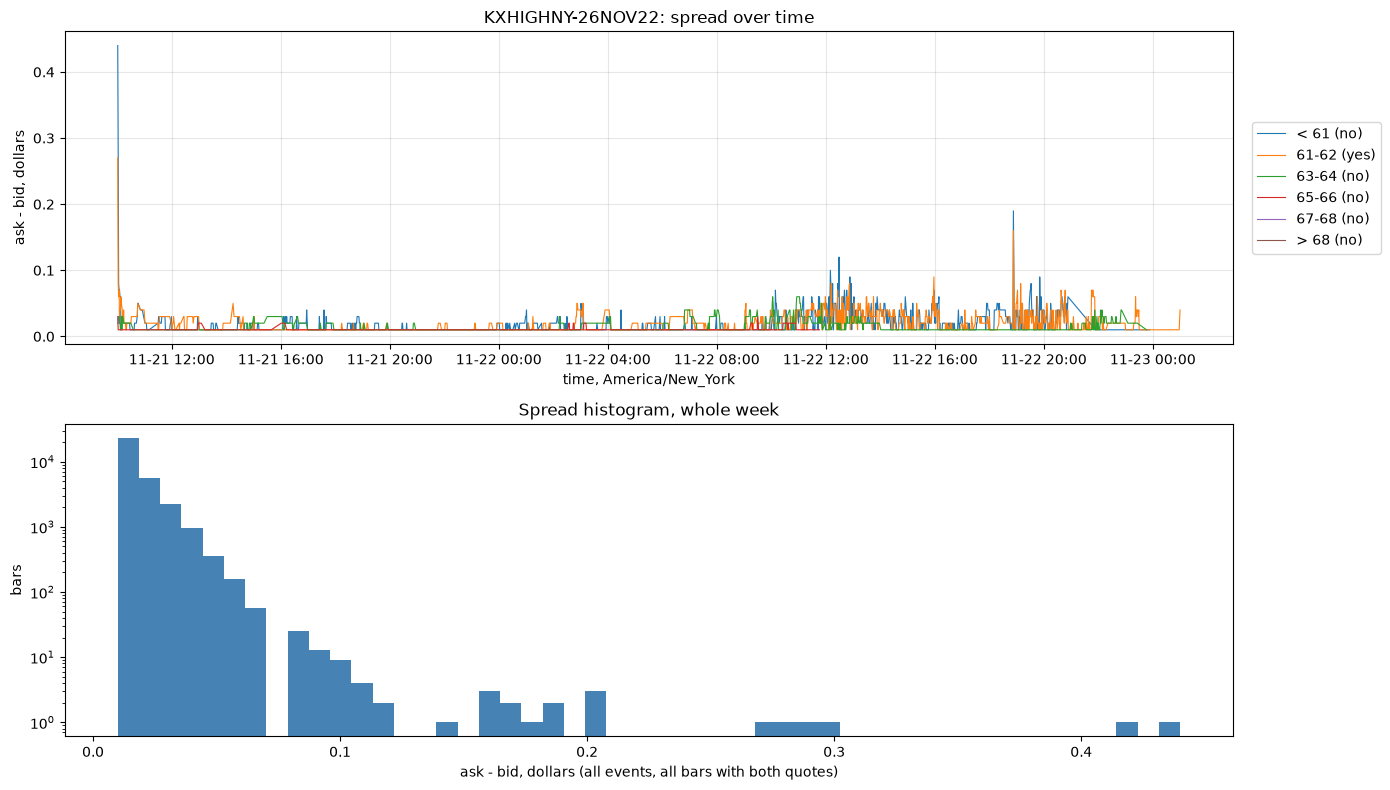

bars with both quotes: 32431 of 41158
spread <= 0 : 0
count    32431.000
mean         0.015
std          0.011
min          0.010
25%          0.010
50%          0.010
75%          0.020
max          0.440
Name: spread, dtype: float64


In [5]:
both = candle.dropna(subset=["yes_bid", "yes_ask"]).copy()
both["spread"] = both["yes_ask"] - both["yes_bid"]

fig, (ax_time, ax_hist) = plt.subplots(2, 1, figsize=(14, 8))
ev_both = both[both["event_ticker"] == EVENT]
for i, m in enumerate(ev_markets.itertuples()):
    one = ev_both[ev_both["market_ticker"] == m.ticker]
    ax_time.plot(one["ts_ny"], one["spread"], color=colors[i], label=m.label, linewidth=0.8)
ax_time.set_xlabel("time, America/New_York")
ax_time.set_ylabel("ask - bid, dollars")
ax_time.set_title(f"{EVENT}: spread over time")
ax_time.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M", tz=TZ))
ax_time.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
ax_time.grid(alpha=0.3)

ax_hist.hist(both["spread"], bins=50, color="steelblue")
ax_hist.set_xlabel("ask - bid, dollars (all events, all bars with both quotes)")
ax_hist.set_ylabel("bars")
ax_hist.set_title("Spread histogram, whole week")
ax_hist.set_yscale("log")
fig.tight_layout()
plt.show()

print("bars with both quotes:", len(both), "of", len(candle))
print("spread <= 0 :", int((both["spread"] <= 0).sum()))
print(both["spread"].describe().round(3))

## 6. Sanity check: sum of mid prices

The six buckets are mutually exclusive, so the sum of their mid prices should sit near 1.0. Each market's last mid is carried forward on a 1-minute grid; the sum starts once every market has a mid. A market that never has both a bid and an ask is left out (and listed), so the sum can then fall short of 1.

markets left out (never had both bid and ask): ['> 68 (no)']


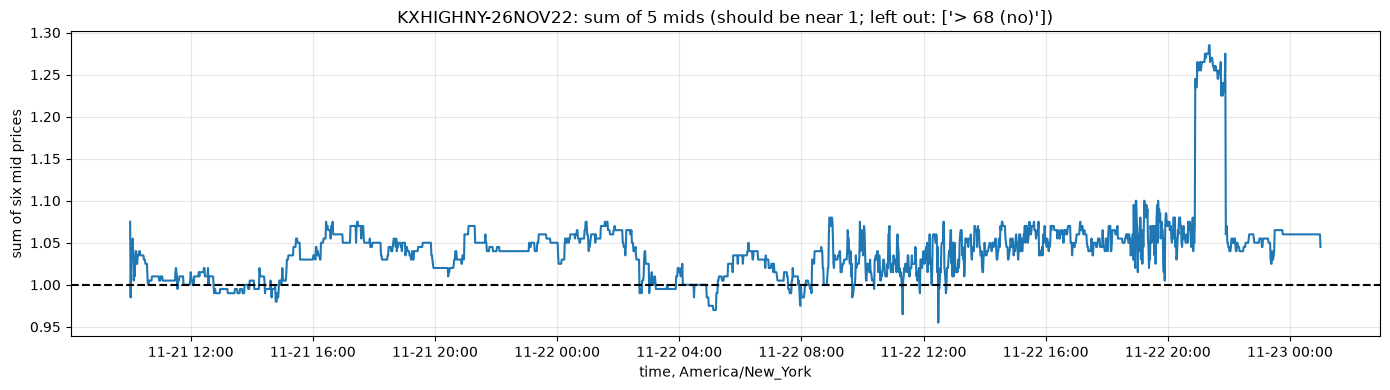

count    2340.000
mean        1.041
std         0.043
min         0.955
25%         1.015
50%         1.040
75%         1.055
max         1.285
dtype: float64


In [6]:
grid = pd.date_range(ev_candles["ts"].min().floor("min"), ev_candles["ts"].max().ceil("min"), freq="1min")
mids = pd.DataFrame(index=grid)
for m in ev_markets.itertuples():
    one = ev_candles[ev_candles["market_ticker"] == m.ticker].set_index("ts")
    mid = ((one["yes_bid"] + one["yes_ask"]) / 2).dropna()   # only where both exist
    on_grid = mid.reindex(mid.index.union(grid)).ffill().reindex(grid)
    mids[m.label] = on_grid

# A market that never has both quotes has no mid at all; leave it out of the sum and say so.
no_mid = mids.columns[mids.isna().all()].tolist()
mids = mids.drop(columns=no_mid)
print("markets left out (never had both bid and ask):", no_mid)
mid_sum = mids.sum(axis=1, min_count=len(mids.columns))   # NaN until every remaining market has a mid

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(mid_sum.index.tz_convert(TZ), mid_sum.values)
ax.axhline(1.0, color="black", linestyle="--")
ax.set_xlabel("time, America/New_York")
ax.set_ylabel("sum of six mid prices")
ax.set_title(f"{EVENT}: sum of {len(mids.columns)} mids (should be near 1; left out: {no_mid})")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M", tz=TZ))
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print(mid_sum.describe().round(3))

## 7. Last quote vs result

Markets that resolved yes should end near 1, the others near 0.

In [7]:
before_close = candle.merge(market[["ticker", "close_time"]], left_on="market_ticker", right_on="ticker")
before_close = before_close[before_close["ts"] <= before_close["close_time"]].sort_values("ts")
last = before_close.groupby("market_ticker").agg(last_bar=("ts", "last"), last_bid=("yes_bid", "last"), last_ask=("yes_ask", "last"))

final = market.set_index("ticker")[["event_ticker", "label", "result"]].join(last)
final["last_bar"] = final["last_bar"].dt.tz_convert(TZ)
final.sort_values(["event_ticker"], kind="stable").reset_index(drop=True)

,event_ticker,label,result,last_bar,last_bid,last_ask
0,KXHIGHNY-26NOV16,< 52 (no),no,2026-11-17 01:00:00-05:00,0.01,0.01
1,KXHIGHNY-26NOV16,52-53 (no),no,2026-11-17 01:00:00-05:00,0.01,0.01
2,KXHIGHNY-26NOV16,54-55 (yes),yes,2026-11-17 00:44:00-05:00,0.99,0.99
3,KXHIGHNY-26NOV16,56-57 (no),no,2026-11-17 00:47:00-05:00,0.01,0.01
4,KXHIGHNY-26NOV16,58-59 (no),no,2026-11-17 01:00:00-05:00,0.01,0.01
5,KXHIGHNY-26NOV16,> 59 (no),no,2026-11-17 01:00:00-05:00,NaN,0.01
6,KXHIGHNY-26NOV17,< 55 (no),no,2026-11-18 01:00:00-05:00,0.01,0.01
7,KXHIGHNY-26NOV17,55-56 (no),no,2026-11-18 01:00:00-05:00,0.12,0.01
8,KXHIGHNY-26NOV17,57-58 (yes),yes,2026-11-18 01:00:00-05:00,0.99,0.87
9,KXHIGHNY-26NOV17,59-60 (no),no,2026-11-18 01:00:00-05:00,0.02,0.01
